# Кластеризация городов методом K-means

Лабораторная работа по кластерному анализу. Датасет Economics of Cities: 48 городов мира, 1991 год.

## 1. Постановка задачи

Нужно выяснить, на какое число групп естественно делятся города по трём показателям: годовой рабочей нагрузке (`Work`), уровню цен (`Price`) и уровню оплаты труда (`Salary`). Метод - K-means с числом кластеров от 2 до 8.

Особое внимание уделяется сравнению `k=2` и `k=3`. Внутренние метрики качества обычно выше у более грубого разбиения, но дополнительный кластер может давать более полезную сегментацию. Работа должна показать, чем именно выигрывает и проигрывает третий кластер, и только после этого обосновать выбор. Отдельно проверяется устойчивость K-means к начальным состояниям: алгоритм находит локальный, а не глобальный минимум, и результат может зависеть от случайной инициализации.

Ноутбук самостоятельный: чтобы его выполнить, нужен только файл `Econom_Cities_data.csv` рядом с ним.

Подключаем библиотеки и задаём константы. Единые названия признаков и список метрик объявлены один раз, чтобы дальше не повторять их в коде.

In [1]:
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy.spatial.distance import cdist, pdist
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (adjusted_rand_score, calinski_harabasz_score,
                             davies_bouldin_score, silhouette_samples,
                             silhouette_score)
from sklearn.preprocessing import StandardScaler

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 110

DATA_PATH = 'Econom_Cities_data.csv'
MISSING_CODE = -9999
FEATURES = ['Work', 'Price', 'Salary']
METRIC_COLUMNS = [
    'silhouette', 'davies_bouldin', 'calinski_harabasz', 'dunn'
]
RANDOM_STATE = 42

## 2. Описание данных

Файл `Econom_Cities_data.csv` содержит 48 городов мира и три числовых показателя за 1991 год:

| Признак | Смысл |
|---|---|
| `Work` | годовая рабочая нагрузка (порядок значений 1600-2400 соответствует числу рабочих часов в год) |
| `Price` | уровень цен на потребительскую корзину, индекс |
| `Salary` | уровень оплаты труда, индекс (максимум 100 у Цюриха) |

Единицы измерения в самом файле не описаны, поэтому `Price` и `Salary` трактуются как относительные индексы, а все выводы о «высоких» и «низких» значениях носят сравнительный характер.

Столбец `City` служит только для идентификации наблюдений и подписей на графиках. В расчёт расстояний он не входит.

В файле три технические особенности: столбцы разделены символом `;`, десятичным разделителем служит запятая, а пропуски закодированы числом `-9999`. Если оставить это число как есть, оно станет огромным выбросом и полностью исказит расстояния, поэтому на этапе загрузки его нужно заменить на настоящий пропуск.

## 3. Предобработка данных

Сначала загружаем файл с правильными разделителями и смотрим, сколько значений `-9999` содержит каждый признак.

In [2]:
raw = pd.read_csv(DATA_PATH, sep=';', decimal=',')
print(f'Строк: {raw.shape[0]}, столбцов: {raw.shape[1]}')
print(raw.dtypes, end='\n\n')

missing_mask = raw[FEATURES].eq(MISSING_CODE)
print('Количество значений -9999 по признакам:')
print(missing_mask.sum(), end='\n\n')
raw[missing_mask.any(axis=1)]

Строк: 48, столбцов: 4
City          str
Work        int64
Price     float64
Salary    float64
dtype: object

Количество значений -9999 по признакам:
Work      2
Price     0
Salary    2
dtype: int64



,City,Work,Price,Salary
6,Cairo,-9999,37.1,-9999.0
17,Jakarta,-9999,43.6,-9999.0


Пропуски есть у двух городов, Каира и Джакарты, и у обоих отсутствуют сразу `Work` и `Salary`. Остаётся один признак из трёх (`Price`). Заполнять два недостающих показателя по одному оставшемуся было бы выдумыванием данных: любая оценка зарплаты и рабочей нагрузки по цене скрыла бы как раз ту информацию, ради которой строится кластеризация. Среднее или медиана по выборке притянули бы оба города к центру облака и исказили бы расстояния. Поэтому эти два города исключаются из основной модели, а не восстанавливаются. Потеря небольшая: 2 из 48 наблюдений.

In [3]:
data = raw.replace(MISSING_CODE, np.nan)
clean = data.dropna(subset=FEATURES).reset_index(drop=True)
excluded = sorted(set(data['City']) - set(clean['City']))
print(f'Исключено городов: {len(excluded)} ({", ".join(excluded)})')
print(f'В анализе: {len(clean)} городов')

Исключено городов: 2 (Cairo, Jakarta)
В анализе: 46 городов


Теперь проверяем, нет ли повторяющихся строк и названий, и смотрим базовые характеристики признаков в исходных единицах. Эти цифры понадобятся позже, чтобы сопоставлять профили кластеров с общим фоном.

In [4]:
print('Полных дубликатов строк:', raw.duplicated().sum())
print('Повторяющихся названий городов:', raw['City'].duplicated().sum())
print('Дубликатов по значениям признаков:',
      clean.duplicated(subset=FEATURES).sum())
clean[FEATURES].describe().round(2)

Полных дубликатов строк: 0
Повторяющихся названий городов: 0
Дубликатов по значениям признаков: 0


,Work,Price,Salary
count,46.00,46.00,46.00
mean,1879.91,70.10,39.55
std,174.34,21.39,24.76
min,1583.00,30.30,2.70
25%,1745.25,51.78,14.38
50%,1849.00,70.95,43.65
75%,1976.25,81.90,59.70
max,2375.00,115.50,100.00


Признаки измеряются в разных масштабах: `Work` меняется в тысячах, а `Price` и `Salary` в десятках. Без стандартизации евклидово расстояние определялось бы почти только `Work`. `StandardScaler` приводит каждый признак к нулевому среднему и единичному стандартному отклонению, и все три показателя вносят в расстояние сопоставимый вклад. Кластеризация далее выполняется на этих трёх стандартизированных признаках.

In [5]:
scaler = StandardScaler()
X = scaler.fit_transform(clean[FEATURES])
print('Средние:', X.mean(axis=0).round(3))
print('Стандартные отклонения:', X.std(axis=0).round(3))

Средние: [ 0. -0.  0.]
Стандартные отклонения: [1. 1. 1.]


## 4. Разведочный анализ

Смотрим распределения признаков, связи между ними и общую геометрию облака точек. От этого зависит, чего ожидать от кластеризации: есть ли выбросы, насколько признаки дублируют друг друга и можно ли показать данные на плоскости без заметной потери информации.

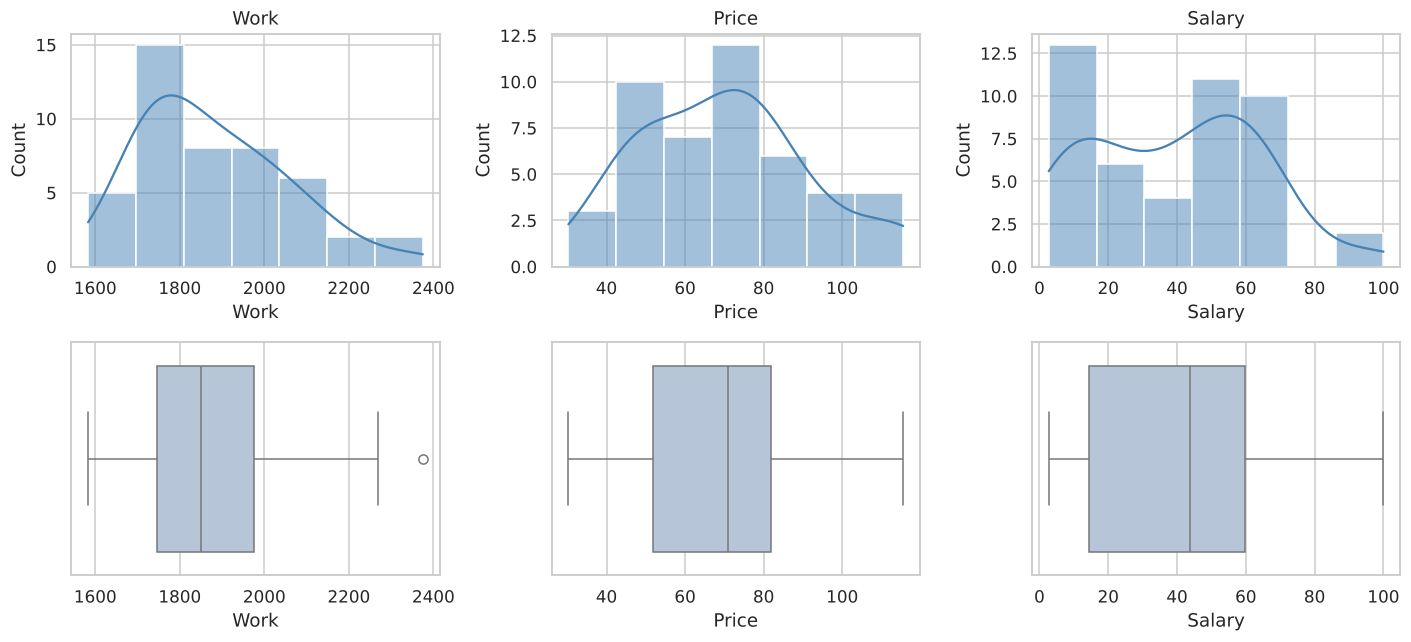

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(13, 6))
for col, feature in enumerate(FEATURES):
    sns.histplot(clean[feature], kde=True, ax=axes[0, col],
                 color='steelblue')
    sns.boxplot(x=clean[feature], ax=axes[1, col], color='lightsteelblue')
    axes[0, col].set_title(feature)
plt.tight_layout()
plt.show()

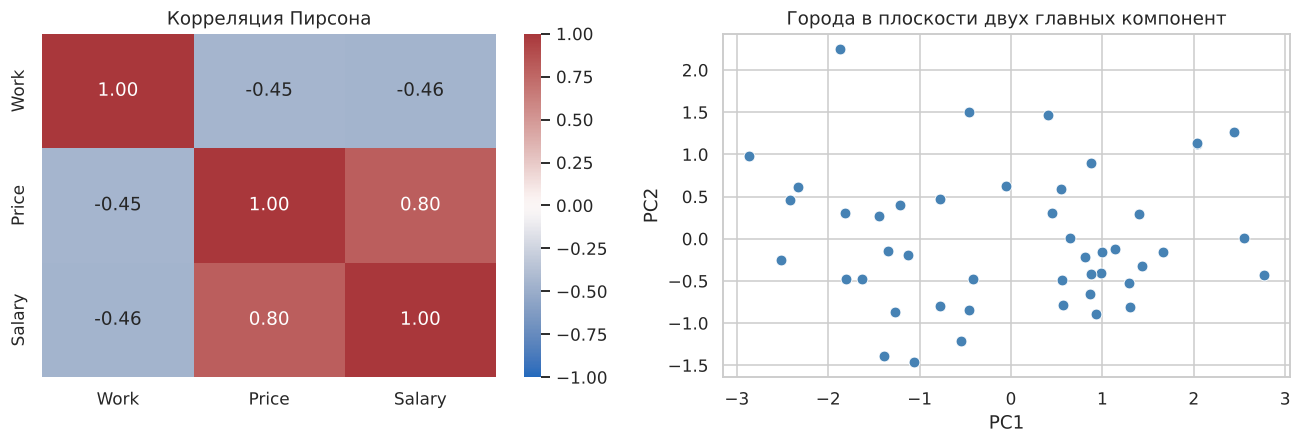

Доля дисперсии PC1 и PC2: [0.72  0.215]
Суммарно: 0.935


,PC1,PC2
Work,-0.48,0.87
Price,0.62,0.35
Salary,0.62,0.34


In [7]:
corr = clean[FEATURES].corr()
pca = PCA(n_components=2, random_state=RANDOM_STATE)
pca_coords = pca.fit_transform(X)
loadings = pd.DataFrame(pca.components_.T, index=FEATURES,
                        columns=['PC1', 'PC2']).round(2)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='vlag', vmin=-1, vmax=1,
            ax=axes[0])
axes[0].set_title('Корреляция Пирсона')
sns.scatterplot(x=pca_coords[:, 0], y=pca_coords[:, 1], ax=axes[1],
                color='steelblue', s=50)
axes[1].set_xlabel('PC1')
axes[1].set_ylabel('PC2')
axes[1].set_title('Города в плоскости двух главных компонент')
plt.tight_layout()
plt.show()

print('Доля дисперсии PC1 и PC2:', pca.explained_variance_ratio_.round(3))
print('Суммарно:', pca.explained_variance_ratio_.sum().round(3))
loadings

Что видно из этих графиков и расчётов:

- Распределение `Work` скошено вправо (коэффициент асимметрии около 0,77): основная масса городов работает 1700-2000 часов в год, а несколько городов заметно выше. Для `Salary` и `Price` асимметрия слабее.
- `Price` и `Salary` сильно связаны (корреляция около 0,80). `Work` отрицательно связан с обоими показателями (около -0,45): чем выше нагрузка, тем в среднем ниже и цены, и зарплаты.
- Две первые главные компоненты объясняют примерно 93 % дисперсии, поэтому проекция на плоскость почти не теряет структуру. PC1 в основном противопоставляет «дорогие и высокооплачиваемые» города «дешёвым и малооплачиваемым» и в первую очередь опирается на `Price` и `Salary`, а PC2 в основном отражает `Work`.

Сильная связь `Price` и `Salary` означает, что эти два признака частично дублируют друг друга и «вес» этой оси в расстоянии выше, чем у `Work`. Это стоит помнить при интерпретации. PCA используется только для рисунков: все модели обучаются на трёх исходных стандартизированных признаках.

## 5. Теоретическое описание метода

K-means делит объекты на `k` групп, минимизируя сумму квадратов расстояний от каждого объекта до центроида своего кластера. Эта сумма называется инерцией (inertia, внутрикластерная сумма квадратов). Алгоритм Ллойда чередует два шага: каждый объект относится к ближайшему центроиду, затем центроиды пересчитываются как средние по своим кластерам. Процесс останавливается, когда назначения перестают меняться.

Важные свойства:

- Алгоритм сходится к локальному минимуму, и результат зависит от начальных центроидов. Поэтому используется инициализация k-means++ и несколько перезапусков (`n_init`): из них выбирается решение с минимальной инерцией.
- Инерция монотонно убывает с ростом `k`, поэтому сама по себе не позволяет выбрать число кластеров. Используется метод локтя: ищется `k`, после которого выигрыш в инерции резко замедляется.
- Метод неявно предполагает компактные, примерно сферические кластеры сопоставимого размера, потому что граница между кластерами всегда прямая (равноудалённая от центроидов).
- Устойчивость решения оценивается через Adjusted Rand Index (ARI): он сравнивает два разбиения одних и тех же объектов и равен 1 при полном совпадении, около 0 при случайном совпадении. Номера кластеров при этом не важны.


### Метрики качества

Для оценки разбиений применяются четыре внутренних индекса. Они опираются на разные свойства кластеров, и их значения нельзя сводить в один общий рейтинг.

| Метрика | Что измеряет | Как читать |
|---|---|---|
| Silhouette | для каждого объекта сравнивает среднее расстояние до своего кластера и до ближайшего чужого; затем усредняется | от -1 до 1, чем выше, тем лучше |
| Davies-Bouldin | среднюю «похожесть» каждого кластера на самого близкого соседа: отношение суммарного разброса к расстоянию между центрами | чем ниже, тем лучше |
| Calinski-Harabasz | отношение межкластерной дисперсии к внутрикластерной с поправкой на число кластеров | чем выше, тем лучше |
| Dunn | наименьшее расстояние между двумя кластерами, делённое на наибольший диаметр кластера | чем выше, тем лучше |

Особенности, важные для интерпретации. Calinski-Harabasz и Davies-Bouldin неявно ориентированы на компактные округлые кластеры. Dunn зависит только от двух экстремальных расстояний, поэтому один необычный город заметно меняет его значение. Silhouette полезен ещё и тем, что даёт оценку для каждого города, а не только общую. Все четыре индекса не учитывают содержательный смысл групп, поэтому дополнительно рассматриваются размеры кластеров и профили в исходных единицах.

## 6. Обоснование выбора параметров

**Число кластеров.** Диапазон от 2 до 8: единственный кластер не оценивается метриками, а при 46 городах восемь групп - это уже около 5-6 городов в группе, дальше дробить бессмысленно.

**Инициализация.** `n_init=50`: для каждого `k` алгоритм запускается 50 раз из разных начальных точек, и сохраняется лучшее решение. Для выборки из 46 объектов это дёшево и делает результат практически независимым от удачной инициализации. `random_state=42` фиксирует воспроизводимость.

**Признаки.** Все три стандартизированных признака, без PCA. Расстояние евклидово, как того требует сам алгоритм.

Сначала подключаем вспомогательные функции.

Собираем функции, которые будут вызываться много раз. Индекс Данна в `scikit-learn` отсутствует, поэтому он реализован самостоятельно через матрицы попарных расстояний: `pdist` даёт диаметры кластеров, `cdist` даёт расстояния между объектами разных кластеров.

In [8]:
def dunn_index(points, labels):
    groups = [points[labels == c] for c in np.unique(labels)]
    max_diameter = max(
        pdist(group).max() if len(group) > 1 else 0.0 for group in groups
    )
    min_separation = min(
        cdist(first, second).min()
        for i, first in enumerate(groups)
        for second in groups[i + 1:]
    )
    return min_separation / max_diameter


def evaluate_partition(points, labels):
    return {
        'silhouette': silhouette_score(points, labels),
        'davies_bouldin': davies_bouldin_score(points, labels),
        'calinski_harabasz': calinski_harabasz_score(points, labels),
        'dunn': dunn_index(points, labels),
    }


def format_sizes(labels):
    counts = pd.Series(labels).value_counts().sort_values(ascending=False)
    return ' / '.join(str(n) for n in counts.values)

In [9]:
def relabel_by_salary(labels, salary):
    order = pd.Series(salary).groupby(labels).mean().sort_values().index
    mapping = {old: new for new, old in enumerate(order, start=1)}
    return np.array([mapping[label] for label in labels])


def cluster_profile(frame, labels):
    grouped = frame.assign(cluster=labels).groupby('cluster')[FEATURES]
    profile = pd.concat([
        grouped.size().rename('n'),
        grouped.mean().round(1).add_suffix('_mean'),
        grouped.median().round(1).add_suffix('_median'),
    ], axis=1)
    return profile


def print_cities(frame, labels):
    names = frame['City'].str.replace('_', ' ')
    for cluster, group in names.groupby(labels):
        title = 'Шум' if cluster == -1 else f'Кластер {cluster}'
        print(f'  {title} ({len(group)}): {", ".join(group)}')


def weak_cities(frame, points, labels, threshold=0.25):
    table = pd.DataFrame({
        'city': frame['City'].str.replace('_', ' '),
        'cluster': labels,
        'silhouette': silhouette_samples(points, labels).round(3),
    })
    return table[table['silhouette'] < threshold].sort_values('silhouette')


def silhouette_summary(points, labels):
    values = silhouette_samples(points, labels)
    return pd.DataFrame({'cluster': labels, 'value': values}).groupby(
        'cluster')['value'].agg(
        n='size', mean='mean', min='min',
        below_zero=lambda s: int((s < 0).sum()),
        below_025=lambda s: int((s < 0.25).sum()),
    ).round(3)

In [10]:
def plot_clusters(ax, labels, title, annotate=True):
    palette = sns.color_palette('Set2', 8)
    for cluster in np.unique(labels):
        mask = labels == cluster
        if cluster == -1:
            ax.scatter(pca_coords[mask, 0], pca_coords[mask, 1], s=55,
                       color='gray', marker='x', label='Шум')
        else:
            ax.scatter(pca_coords[mask, 0], pca_coords[mask, 1], s=60,
                       color=palette[cluster - 1], edgecolor='white',
                       label=f'Кластер {cluster}')
    if annotate:
        names = clean['City'].str.replace('_', ' ')
        for (x_pos, y_pos), name in zip(pca_coords, names):
            ax.annotate(name, (x_pos, y_pos), fontsize=7.5,
                        xytext=(3, 3), textcoords='offset points')
    ratio = pca.explained_variance_ratio_
    ax.set_xlabel(f'PC1 ({ratio[0]:.0%})')
    ax.set_ylabel(f'PC2 ({ratio[1]:.0%})')
    ax.set_title(title)
    ax.legend(loc='best', fontsize=8)


def plot_feature_boxes(labels, suptitle):
    frame = clean.assign(cluster=labels)
    base = sns.color_palette('Set2', 8)
    palette = {
        cluster: 'gray' if cluster == -1 else base[cluster - 1]
        for cluster in np.unique(labels)
    }
    fig, axes = plt.subplots(1, 3, figsize=(13, 4))
    for ax, feature in zip(axes, FEATURES):
        sns.boxplot(data=frame, x='cluster', y=feature, hue='cluster',
                    palette=palette, legend=False, ax=ax)
        sns.stripplot(data=frame, x='cluster', y=feature, color='black',
                      size=3, alpha=0.6, ax=ax)
        ax.set_title(feature)
    fig.suptitle(suptitle)
    plt.tight_layout()
    plt.show()

## 7. Построение модели

Обучаем K-means для каждого `k` от 2 до 8 и сохраняем инерцию, четыре метрики и размеры кластеров. Номера кластеров упорядочены по возрастанию средней зарплаты (кластер 1 - самая низкая), поскольку исходные номера K-means случайны и не пригодны для сравнения решений между собой.

In [11]:
K_RANGE = range(2, 9)
N_INIT = 50

models = {}
partitions = {}
rows = []
for k in K_RANGE:
    model = KMeans(n_clusters=k, n_init=N_INIT, random_state=RANDOM_STATE)
    model.fit(X)
    labels = relabel_by_salary(model.labels_, clean['Salary'])
    models[k] = model
    partitions[k] = labels
    rows.append({
        'k': k,
        'inertia': model.inertia_,
        **evaluate_partition(X, labels),
        'min_size': int(np.bincount(labels)[1:].min()),
        'sizes': format_sizes(labels),
    })
results = pd.DataFrame(rows)
display(results.round(3))

,k,inertia,silhouette,davies_bouldin,calinski_harabasz,dunn,min_size,sizes
0,2,61.117,0.470,0.808,55.351,0.223,21,25 / 21
1,3,47.361,0.388,0.905,41.146,0.144,10,25 / 11 / 10
2,4,35.553,0.366,1.063,40.342,0.165,6,19 / 11 / 10 / 6
3,5,27.763,0.375,0.907,40.699,0.145,6,14 / 11 / 8 / 7 / 6
4,6,23.213,0.373,0.933,39.560,0.145,5,14 / 8 / 7 / 6 / 6 / 5
5,7,18.701,0.397,0.823,41.466,0.193,2,14 / 9 / 7 / 6 / 4 / 4 / 2
6,8,15.309,0.396,0.786,43.506,0.228,2,14 / 8 / 7 / 5 / 4 / 3 / 3 / 2


## 8. Оценка качества кластеризации

Графики показывают, как инерция и четыре метрики меняются с числом кластеров. Последняя панель - размер самого маленького кластера: он помогает заметить, что решение «улучшается» за счёт выделения совсем малой группы.

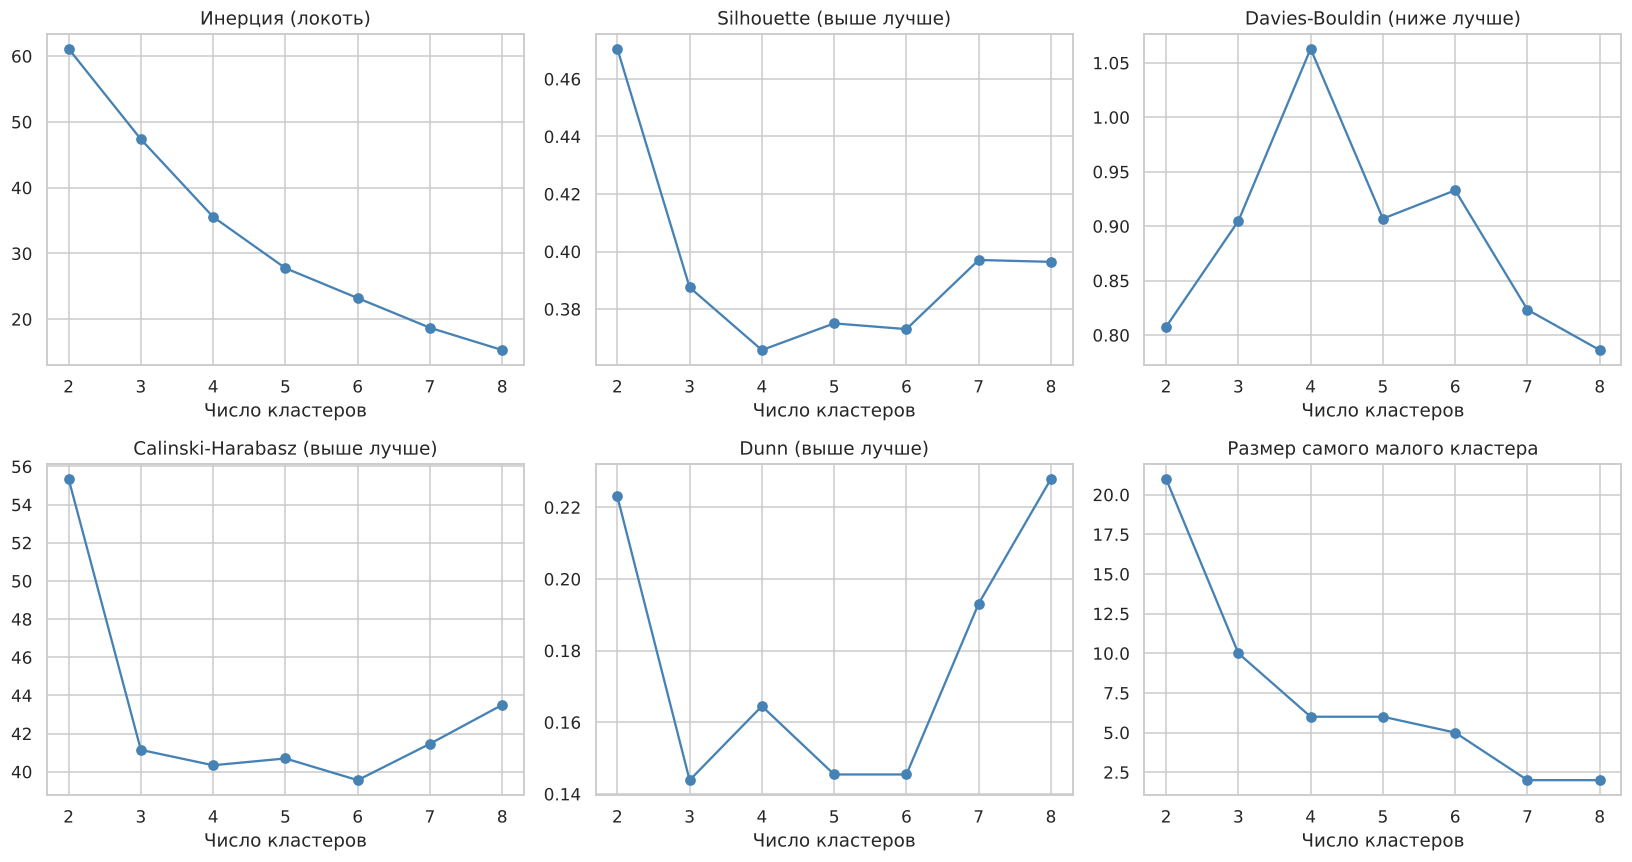

In [12]:
panels = [
    ('inertia', 'Инерция (локоть)'),
    ('silhouette', 'Silhouette (выше лучше)'),
    ('davies_bouldin', 'Davies-Bouldin (ниже лучше)'),
    ('calinski_harabasz', 'Calinski-Harabasz (выше лучше)'),
    ('dunn', 'Dunn (выше лучше)'),
    ('min_size', 'Размер самого малого кластера'),
]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, (column, title) in zip(axes.ravel(), panels):
    ax.plot(results['k'], results[column], marker='o', color='steelblue')
    ax.set_title(title)
    ax.set_xticks(list(K_RANGE))
    ax.set_xlabel('Число кластеров')
plt.tight_layout()
plt.show()

Что показывают графики.

- **Локоть.** Инерция убывает плавно: 61,1 при `k=2`, 47,4, 35,6, 27,8, 23,2, 18,7 и 15,3 при `k=8`. Каждый новый кластер снижает её на 13,8, 11,8, 7,8, 4,6, 4,5 и 3,4. Выраженного локтя нет: кривая лишь слегка выполаживается после `k=4`. Метод локтя сам по себе число кластеров не определяет.
- **Silhouette** максимален при `k=2` (0,470), падает до 0,388 при `k=3`, достигает минимума 0,366 при `k=4` и снова поднимается до 0,397 при `k=7` и 0,396 при `k=8`.
- **Calinski-Harabasz** также максимален при `k=2` (55,35), затем колеблется между 39,6 и 43,5.
- **Davies-Bouldin** растёт от 0,808 (`k=2`) до 1,063 (`k=4`) и снижается до 0,786 при `k=8`. **Dunn** падает с 0,223 до 0,144 при `k=3` и поднимается до 0,228 при `k=8`.
- При `k=8` Davies-Bouldin (0,786) и Dunn (0,228) немного лучше, чем при `k=2`. Но минимальный кластер при `k=7` и `k=8` содержит всего 2 города, размеры при `k=8` равны 14 / 8 / 7 / 5 / 4 / 3 / 3 / 2, и, как показано ниже, такие решения не воспроизводятся стабильно. Поэтому они не принимаются как более удачные.

### Устойчивость к начальным состояниям

Для каждого `k` выполняется 30 запусков с разными `random_state`. Проверяются два режима: один запуск с одной инициализацией (`n_init=1`, самый «шумный» вариант) и запуск с 50 инициализациями, как в основной модели. Для всех пар запусков считается ARI. Среднее значение показывает типичное совпадение, минимум показывает худший случай. Дополнительно считается доля запусков, дошедших до лучшей найденной инерции.

In [13]:
N_RUNS = 30


def stability_report(points, k, n_init):
    runs = [
        KMeans(n_clusters=k, n_init=n_init, random_state=seed).fit(points)
        for seed in range(N_RUNS)
    ]
    ari_values = [
        adjusted_rand_score(first.labels_, second.labels_)
        for first, second in combinations(runs, 2)
    ]
    inertias = np.array([run.inertia_ for run in runs])
    return {
        'k': k,
        'n_init': n_init,
        'ari_mean': np.mean(ari_values),
        'ari_min': np.min(ari_values),
        'share_best_inertia': np.isclose(inertias, inertias.min()).mean(),
    }


stability = pd.DataFrame([
    stability_report(X, k, n_init)
    for n_init in (1, N_INIT) for k in K_RANGE
])
display(stability.round(3))

,k,n_init,ari_mean,ari_min,share_best_inertia
0,2,1,1.000,1.000,1.000
1,3,1,0.621,0.340,0.233
2,4,1,0.558,0.215,0.067
3,5,1,0.600,0.211,0.033
4,6,1,0.648,0.352,0.100
5,7,1,0.633,0.368,0.033
6,8,1,0.698,0.365,0.033
7,2,50,1.000,1.000,1.000
8,3,50,1.000,1.000,1.000
9,4,50,1.000,1.000,1.000


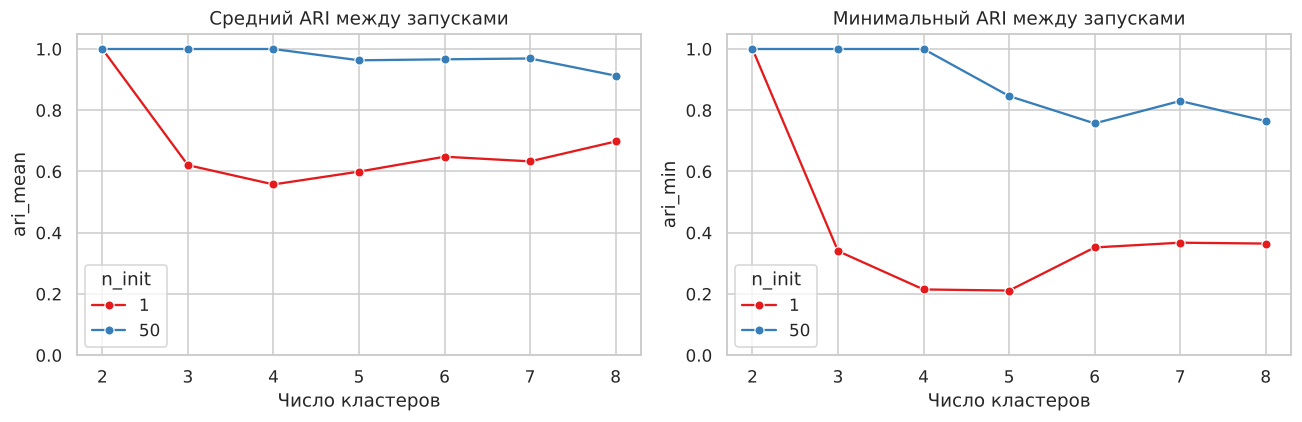

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.lineplot(data=stability, x='k', y='ari_mean', hue='n_init',
             marker='o', palette='Set1', ax=axes[0])
axes[0].set_title('Средний ARI между запусками')
sns.lineplot(data=stability, x='k', y='ari_min', hue='n_init',
             marker='o', palette='Set1', ax=axes[1])
axes[1].set_title('Минимальный ARI между запусками')
for ax in axes:
    ax.set_xticks(list(K_RANGE))
    ax.set_ylim(0, 1.05)
    ax.set_xlabel('Число кластеров')
plt.tight_layout()
plt.show()

Результаты проверки устойчивости.

- При одной инициализации (`n_init=1`) результат зависит от случайного старта. Для `k=3` средний ARI равен 0,62, минимальный 0,34, а лучшую инерцию получают лишь 23 % запусков. Для `k=2` все запуски совпадают (ARI равен 1).
- При `n_init=50` решения для `k=2`, `k=3` и `k=4` полностью воспроизводимы: ARI равен 1 во всех парах, все 30 запусков приходят к одной и той же минимальной инерции.
- Начиная с `k=5` даже 50 инициализаций не гарантируют одного результата: минимальный ARI опускается до 0,76-0,85, средний находится в пределах 0,91-0,97, а лучшей инерции достигают от 20 % (при `k=8`) до 60 % запусков. У таких решений несколько почти равноценных локальных минимумов.

Вывод: основная модель с `n_init=50` надёжна для `k=2` и `k=3`, и различие между ними определяется содержанием, а не нестабильностью алгоритма. Решения с пятью и более кластерами следует интерпретировать осторожно.

### Подробное сравнение двух и трёх кластеров

Сначала проверяем, воспроизводятся ли ориентировочные значения предварительного расчёта.

In [15]:
reference = pd.DataFrame(
    [[0.470, 0.808, 55.351, 0.223], [0.388, 0.905, 41.146, 0.144]],
    index=pd.Index([2, 3], name='k'), columns=METRIC_COLUMNS,
)
recomputed = results[results['k'].isin([2, 3])].set_index('k')
recomputed = recomputed[METRIC_COLUMNS].round(3)
print('Максимальное расхождение с предварительным расчётом:',
      (recomputed - reference).abs().max().max())

Максимальное расхождение с предварительным расчётом: 0.0


In [16]:
compare = results[results['k'].isin([2, 3])]
display(compare.drop(columns='min_size').round(3))
display(pd.crosstab(partitions[2], partitions[3],
                    rownames=['k=2'], colnames=['k=3']))

,k,inertia,silhouette,davies_bouldin,calinski_harabasz,dunn,sizes
0,2,61.117,0.470,0.808,55.351,0.223,25 / 21
1,3,47.361,0.388,0.905,41.146,0.144,25 / 11 / 10


k=3,1,2,3
k=2,,,
1,10,11,0
2,0,0,25


Общий Silhouette скрывает, как уверенность распределена по городам. Для обоих решений смотрим число городов с отрицательным Silhouette и со слабой принадлежностью (меньше 0,25).

In [17]:
for k in (2, 3):
    print(f'K-means, k={k}')
    display(silhouette_summary(X, partitions[k]))
    print('Города с Silhouette ниже 0,25:')
    display(weak_cities(clean, X, partitions[k]))

K-means, k=2


,n,mean,min,below_zero,below_025
cluster,,,,,
1,21,0.450,0.095,0,3
2,25,0.488,0.098,0,1


Города с Silhouette ниже 0,25:


,city,cluster,silhouette
40,Taipei,1,0.095
15,Houston,2,0.098
36,Seoul,1,0.197
1,Athens,1,0.227


K-means, k=3


,n,mean,min,below_zero,below_025
cluster,,,,,
1,10,0.212,-0.029,1,6
2,11,0.476,0.234,0,1
3,25,0.418,0.068,0,3


Города с Silhouette ниже 0,25:


,city,cluster,silhouette
41,Tel Aviv,1,-0.029
3,Bombay,1,0.018
15,Houston,3,0.068
6,Caracas,1,0.081
37,Singpore,1,0.105
0,Amsterdam,3,0.207
40,Taipei,1,0.212
32,Panama,1,0.212
21,Los Angeles,3,0.224
5,Buenos Aires,2,0.234


**Итог сравнения двух и трёх кластеров.**

Все четыре метрики хуже при `k=3`: Silhouette 0,470 → 0,388 (минус 17 %), Davies-Bouldin 0,808 → 0,905 (хуже на 12 %), Calinski-Harabasz 55,4 → 41,1 (минус 26 %), Dunn 0,223 → 0,144 (минус 35 %). Инерция при этом снижается с 61,1 до 47,4, что неизбежно для любого дополнительного кластера.

Таблица пересечений показывает, что третий кластер возникает за счёт деления кластера из 21 города на 10 и 11 городов. Кластер из 25 городов остаётся без изменений.

Оценки Silhouette по городам показывают цену этого деления. При `k=2` отрицательных значений нет, а ниже 0,25 лежат четыре города (Афины, Хьюстон, Сеул, Тайбэй). При `k=3` один город (Тель-Авив) имеет отрицательный Silhouette, а ниже 0,25 лежат десять городов, из которых шесть относятся к кластеру из десяти городов с длинной рабочей нагрузкой. Средний Silhouette этого кластера 0,212, тогда как при `k=2` оба кластера имеют 0,45-0,49.

## 9. Интерпретация результатов

Профили групп считаются в исходных единицах (не в стандартизированных): средние совпадают с центроидами K-means, а медианы помогают понять, не определяются ли средние отдельными городами. Ниже решения с двумя и тремя кластерами.

In [18]:
for k in (2, 3):
    labels = partitions[k]
    print(f'K-means, k={k}: средние и медианные значения признаков')
    display(cluster_profile(clean, labels))
    print('Минимум и максимум признаков по кластерам:')
    display(clean.assign(cluster=labels).groupby('cluster')[FEATURES]
            .agg(['min', 'max']).round(1))
    print_cities(clean, labels)
    print()

K-means, k=2: средние и медианные значения признаков


,n,Work_mean,Price_mean,Salary_mean,Work_median,Price_median,Salary_median
cluster,,,,,,,
1,21,1987.9,52.4,16.3,1971.0,49.8,12.5
2,25,1789.2,85.0,59.0,1768.0,79.8,58.2


Минимум и максимум признаков по кластерам:


Work         Price        Salary       
            min     max   min    max    min    max
cluster                                           
1        1742.0  2375.0  30.3   84.3    2.7   34.5
2        1583.0  2068.0  65.6  115.5   39.2  100.0

  Кластер 1 (21): Athens, Bogota, Bombay, Buenos Aires, Caracas, Hong Kong, Johannesburg, Kuala Lumpur, Lagos, Lisbon, Manila, Mexico City, Nairobi, Nicosia, Panama, Rio de Janeiro, San Paulo, Seoul, Singpore, Taipei, Tel Aviv
  Кластер 2 (25): Amsterdam, Brussels, Chicago, Copenhagen, Dublin, Dusseldorf, Frankfurt, Geneva, Helsinki, Houston, London, Los Angeles, Luxembourg, Madrid, Milan, Montreal, New York, Oslo, Paris, Stockholm, Sydney, Tokyo, Toronto, Vienna, Zurich

K-means, k=3: средние и медианные значения признаков


,n,Work_mean,Price_mean,Salary_mean,Work_median,Price_median,Salary_median
cluster,,,,,,,
1,10,2133.5,54.2,16.1,2111.5,55.1,12.6
2,11,1855.5,50.8,16.6,1842.0,49.8,12.5
3,25,1789.2,85.0,59.0,1768.0,79.8,58.2


Минимум и максимум признаков по кластерам:


Work         Price        Salary       
            min     max   min    max    min    max
cluster                                           
1        2015.0  2375.0  30.3   84.3    4.0   34.5
2        1742.0  1971.0  45.0   58.3    2.7   32.7
3        1583.0  2068.0  65.6  115.5   39.2  100.0

  Кластер 1 (10): Bogota, Bombay, Caracas, Hong Kong, Kuala Lumpur, Manila, Panama, Singpore, Taipei, Tel Aviv
  Кластер 2 (11): Athens, Buenos Aires, Johannesburg, Lagos, Lisbon, Mexico City, Nairobi, Nicosia, Rio de Janeiro, San Paulo, Seoul
  Кластер 3 (25): Amsterdam, Brussels, Chicago, Copenhagen, Dublin, Dusseldorf, Frankfurt, Geneva, Helsinki, Houston, London, Los Angeles, Luxembourg, Madrid, Milan, Montreal, New York, Oslo, Paris, Stockholm, Sydney, Tokyo, Toronto, Vienna, Zurich



Боксплоты показывают разброс внутри кластеров и то, по каким признакам группы реально различаются, а по каким пересекаются.

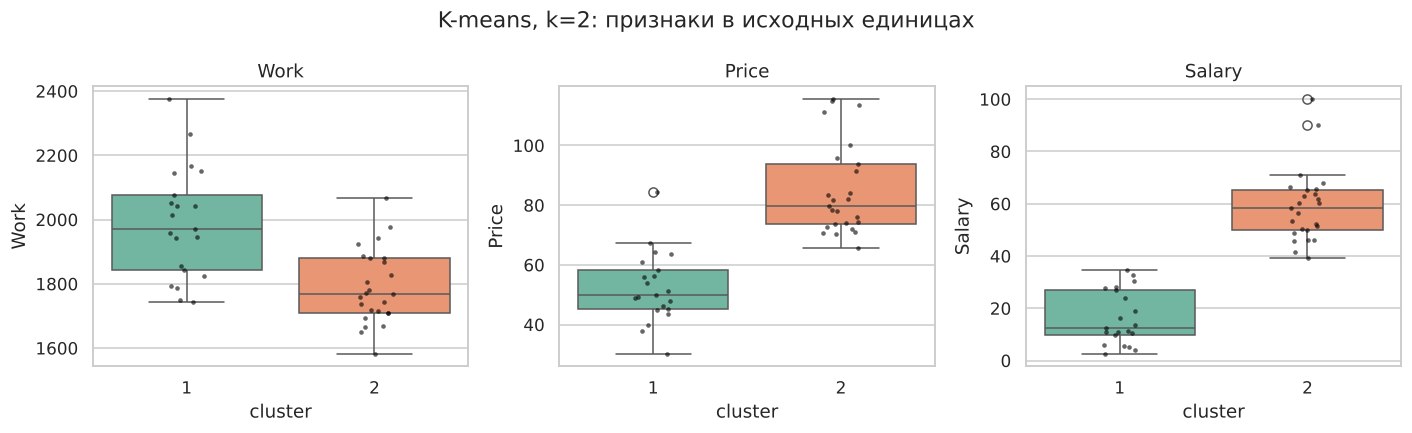

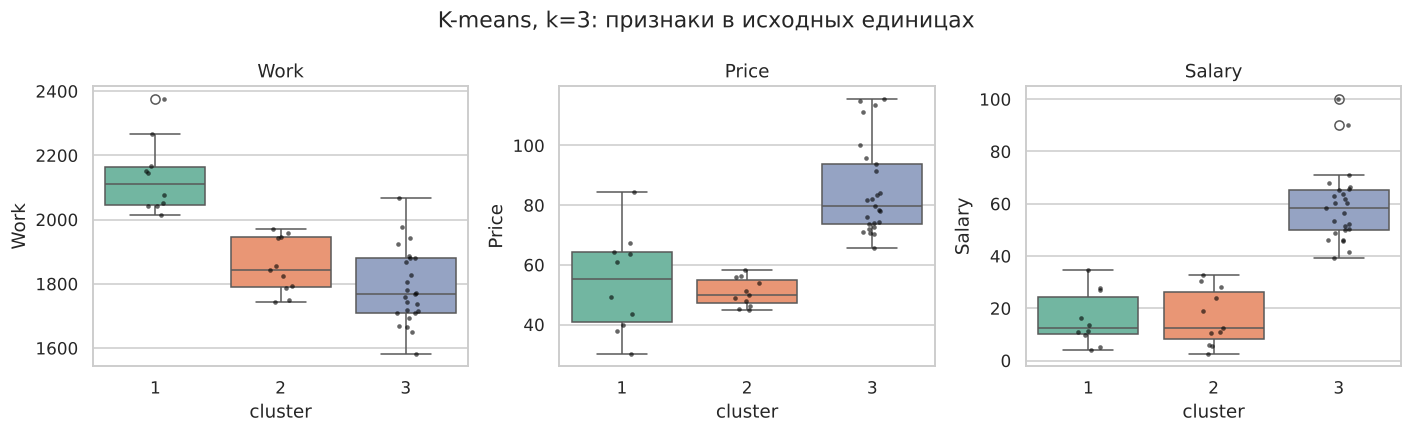

In [19]:
for k in (2, 3):
    plot_feature_boxes(partitions[k],
                       f'K-means, k={k}: признаки в исходных единицах')

Карта городов в плоскости двух главных компонент. Кластеризация выполнена на трёх признаках, PCA нужен только для рисунка.

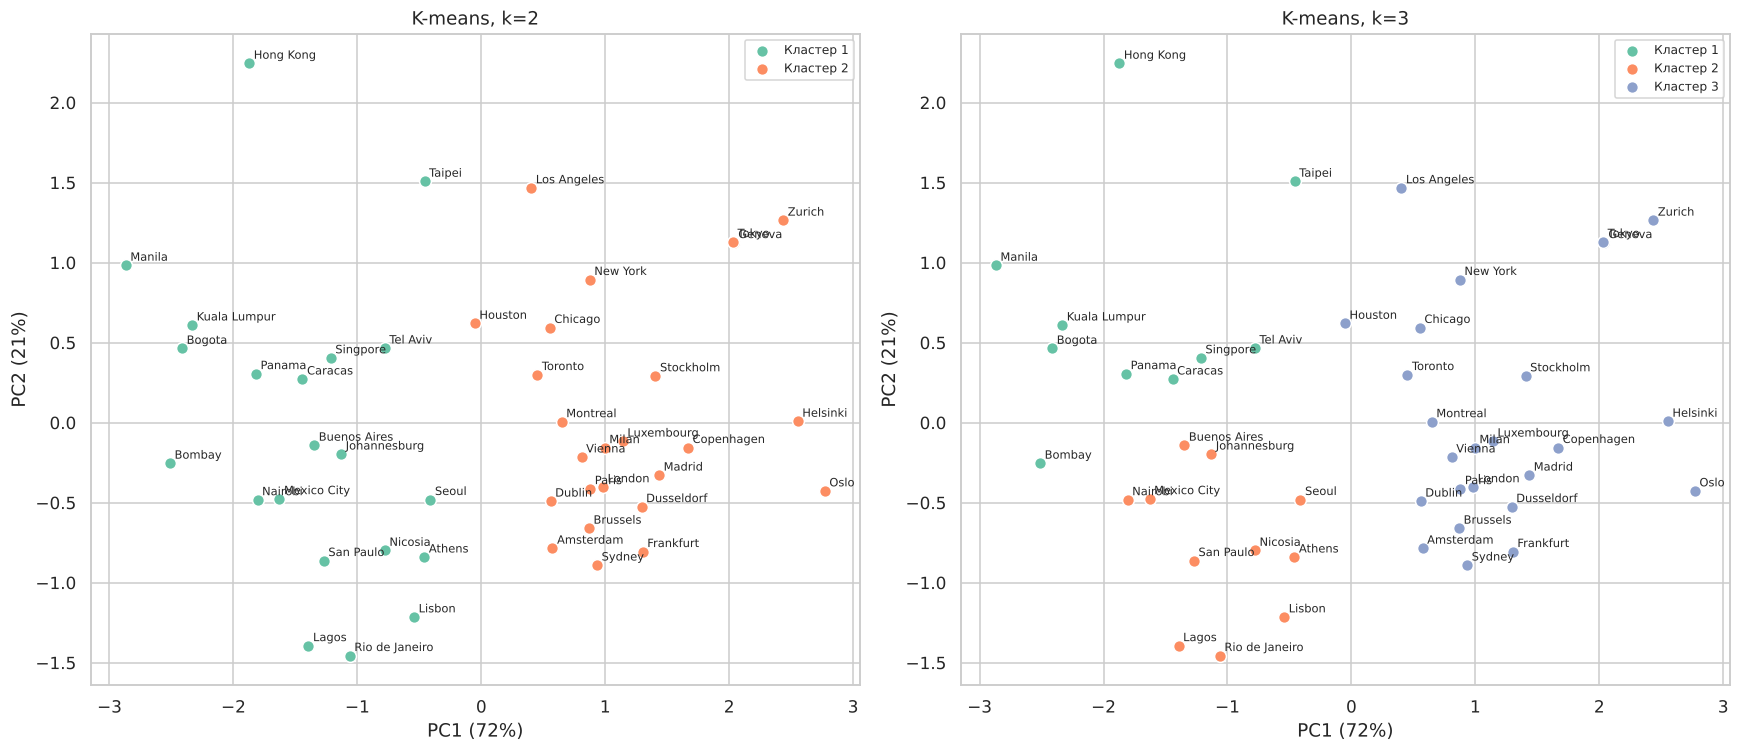

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, k in zip(axes, (2, 3)):
    plot_clusters(ax, partitions[k], f'K-means, k={k}')
plt.tight_layout()
plt.show()

**Два кластера.** Кластер 2 (25 городов): `Work` 1789 часов, `Price` 85,0, `Salary` 59,0. Кластер 1 (21 город): `Work` 1988, `Price` 52,4, `Salary` 16,3. Зарплата в «дорогой» группе выше примерно в 3,6 раза, цены в 1,6 раза, а рабочая нагрузка ниже примерно на 200 часов (10 %). Медианы (58,2 против 12,5 по `Salary`) подтверждают, что различие не создаётся отдельными городами.

**Три кластера.** Кластер 3 (25 городов) остаётся прежним. Кластер из 21 города распадается на кластер 1 (10 городов: `Work` 2134, `Price` 54,2, `Salary` 16,1) и кластер 2 (11 городов: `Work` 1856, `Price` 50,8, `Salary` 16,6). Медианы зарплаты практически совпадают (12,6 и 12,5), цены различаются на несколько пунктов, зато рабочая нагрузка отличается примерно на 280 часов (около 13 %). Диапазоны `Work` не пересекаются: 2015-2375 и 1742-1971 часов, но между ними всего 44 часа. Значит, третий кластер - это деление по одному признаку, `Work`, а граница проходит через непрерывное облако без заметного разрыва.

**Улучшает ли третий кластер интерпретацию.** Отчасти. Он выявляет реальную и содержательную ось, которую двухкластерное решение скрывает: среди дешёвых и малооплачиваемых городов одни работают около 2130 часов в год (Богота, Бомбей, Каракас, Гонконг, Куала-Лумпур, Манила, Панама, Сингапур, Тайбэй, Тель-Авив), другие около 1860 часов (Афины, Буэнос-Айрес, Йоханнесбург, Лагос, Лиссабон, Мехико, Найроби, Никосия, Рио-де-Жанейро, Сан-Паулу, Сеул). Но у этих групп практически одинаковые зарплаты и близкие цены, то есть по двум из трёх признаков деления нет.

## 10. Итоговые выводы

**Наиболее обоснованное решение.** K-means с двумя кластерами: 25 дорогих и высокооплачиваемых городов и 21 город с низкими ценами и зарплатами.

**Почему.** Все четыре метрики лучше при `k=2`, чем при `k=3`: Silhouette 0,470 против 0,388, Davies-Bouldin 0,808 против 0,905, Calinski-Harabasz 55,35 против 41,15, Dunn 0,223 против 0,144. Решение полностью воспроизводимо: при `n_init=50` все запуски дают ARI, равный 1. Значения предварительного расчёта воспроизведены без расхождений.

**Какие метрики противоречат.** Среди всех `k` от 2 до 8 только Davies-Bouldin и Dunn при `k=8` немного лучше, чем при `k=2` (0,786 и 0,228 против 0,808 и 0,223). Но это решение содержит кластеры из 2 и 3 городов и не воспроизводится стабильно (минимальный ARI около 0,77, лучшую инерцию получает лишь 20 % запусков), поэтому в пользу более детального разбиения оно не засчитывается. Метод локтя выраженного перегиба не показывает и в выборе числа кластеров помощи не даёт.

**Баланс.** Кластеры 25 и 21 хорошо сбалансированы. При `k=3` размеры 25 / 11 / 10 также приемлемы, самый малый кластер содержит 10 городов.

**Что отличает кластеры.** Главное различие - зарплата и цены: 59,0 и 85,0 в «дорогой» группе против 16,3 и 52,4 в «дешёвой». Рабочая нагрузка в «дорогой» группе ниже примерно на 200 часов (1789 против 1988).

**Компромисс между двумя и тремя кластерами.** Третий кластер ухудшает все метрики на 12-35 %, делает слабой принадлежность десяти городов (Silhouette ниже 0,25) и разделяет города практически по одному признаку, `Work`, с границей без естественного разрыва. Выигрыш в интерпретации реальный, но ограниченный: он выделяет «дешёвые» города с очень длинной рабочей нагрузкой (около 2130 часов) от остальных (около 1860). Поэтому основным результатом принимается `k=2`, а `k=3` рассматривается как описательное уточнение внутри «низкой» группы. Для задач, где важна именно рабочая нагрузка, трёхкластерное решение допустимо, поскольку оно устойчиво воспроизводится (при `n_init=50` ARI равен 1).

**Ограничения.** Они перечислены в следующем разделе: локальный минимум, предположение о сферических кластерах, чувствительность к выбросам, малая выборка и исключение Каира и Джакарты.

## 11. Ограничения метода

- K-means находит локальный минимум и требует заранее задать `k`. Выбор числа кластеров нельзя полностью автоматизировать: метод локтя и внутренние метрики дают ориентиры, но не однозначный ответ.
- Метод предполагает компактные, примерно сферические кластеры одинакового масштаба. Если группы вытянуты или различаются по плотности, граница между кластерами проходит не там, где её провёл бы человек.
- Центроиды чувствительны к выбросам. Экстремальные города (например, Цюрих по `Salary`) смещают среднее и могут привлекать к себе отдельный кластер.
- Каждый город обязательно попадает в какой-либо кластер, даже если он не похож ни на одну группу: понятия шума в методе нет.
- Выборка мала (46 городов) и состоит из трёх признаков, поэтому оценки устойчивости и метрики качества дают только ориентир.
- Каир и Джакарта исключены из-за пропусков и в кластерах не представлены, что сужает охват городов с низкими ценами и зарплатами.
- Данные относятся к 1991 году, поэтому выводы описывают структуру тех лет.
- Внутренние метрики не являются критерием истины: Calinski-Harabasz и Davies-Bouldin по построению благоволят компактным округлым кластерам, а Dunn определяется двумя экстремальными расстояниями.